<a href="https://colab.research.google.com/github/poojagupthaa14/OIBSIP/blob/main/pooja_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [5]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("Uploaded filename:", filename)

Saving winequality-red.csv.csv to winequality-red.csv (2).csv
Uploaded filename: winequality-red.csv (2).csv


In [6]:
df = pd.read_csv(filename, sep=';')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (1599, 12)

Column Names:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


The dataset contains 1599 rows and 12 columns, including 11 chemical properties and one target variable (quality). All columns contain numerical values, with 11 columns having float data types and the quality column having an integer data type. The statistical summary provides information about the mean, standard deviation, minimum and maximum values of each feature. No missing values are indicated in the dataset information.

4. Checking Missing Values and Duplicate Records

In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate Records:
240


The dataset contains no missing values in any of its columns. However, 240 duplicate records were identified. These duplicate records need to be removed to avoid repeated data and improve the reliability of further analysis and model training.

5. Removing Duplicate Records

In [9]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

print("Duplicate Records:", df.duplicated().sum())

Shape after removing duplicates: (1359, 12)
Duplicate Records: 0


6. Exploratory Data Analysis – Wine Quality Distribution

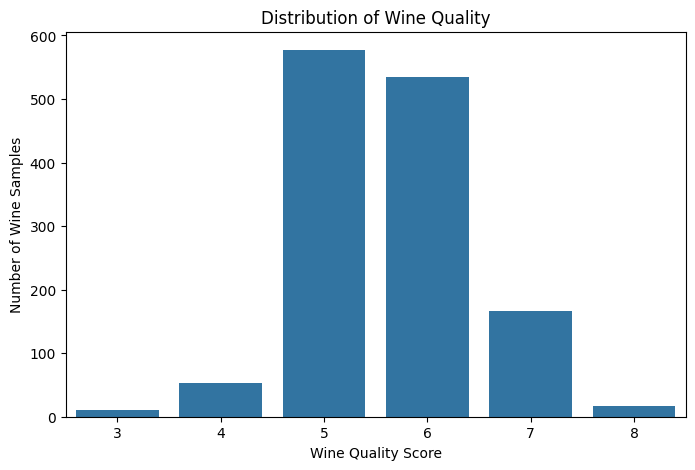

In [10]:
plt.figure(figsize=(8,5))

sns.countplot(x='quality', data=df)

plt.title('Distribution of Wine Quality')
plt.xlabel('Wine Quality Score')
plt.ylabel('Number of Wine Samples')

plt.show()

The count plot shows that wine quality scores 5 and 6 have the highest number of samples, with score 5 being the most frequent. Quality scores 3 and 8 have the lowest number of samples. The distribution is imbalanced, as most wine samples belong to quality scores 5 and 6, while very few belong to the extreme quality categories.

7. Distribution of Chemical Features

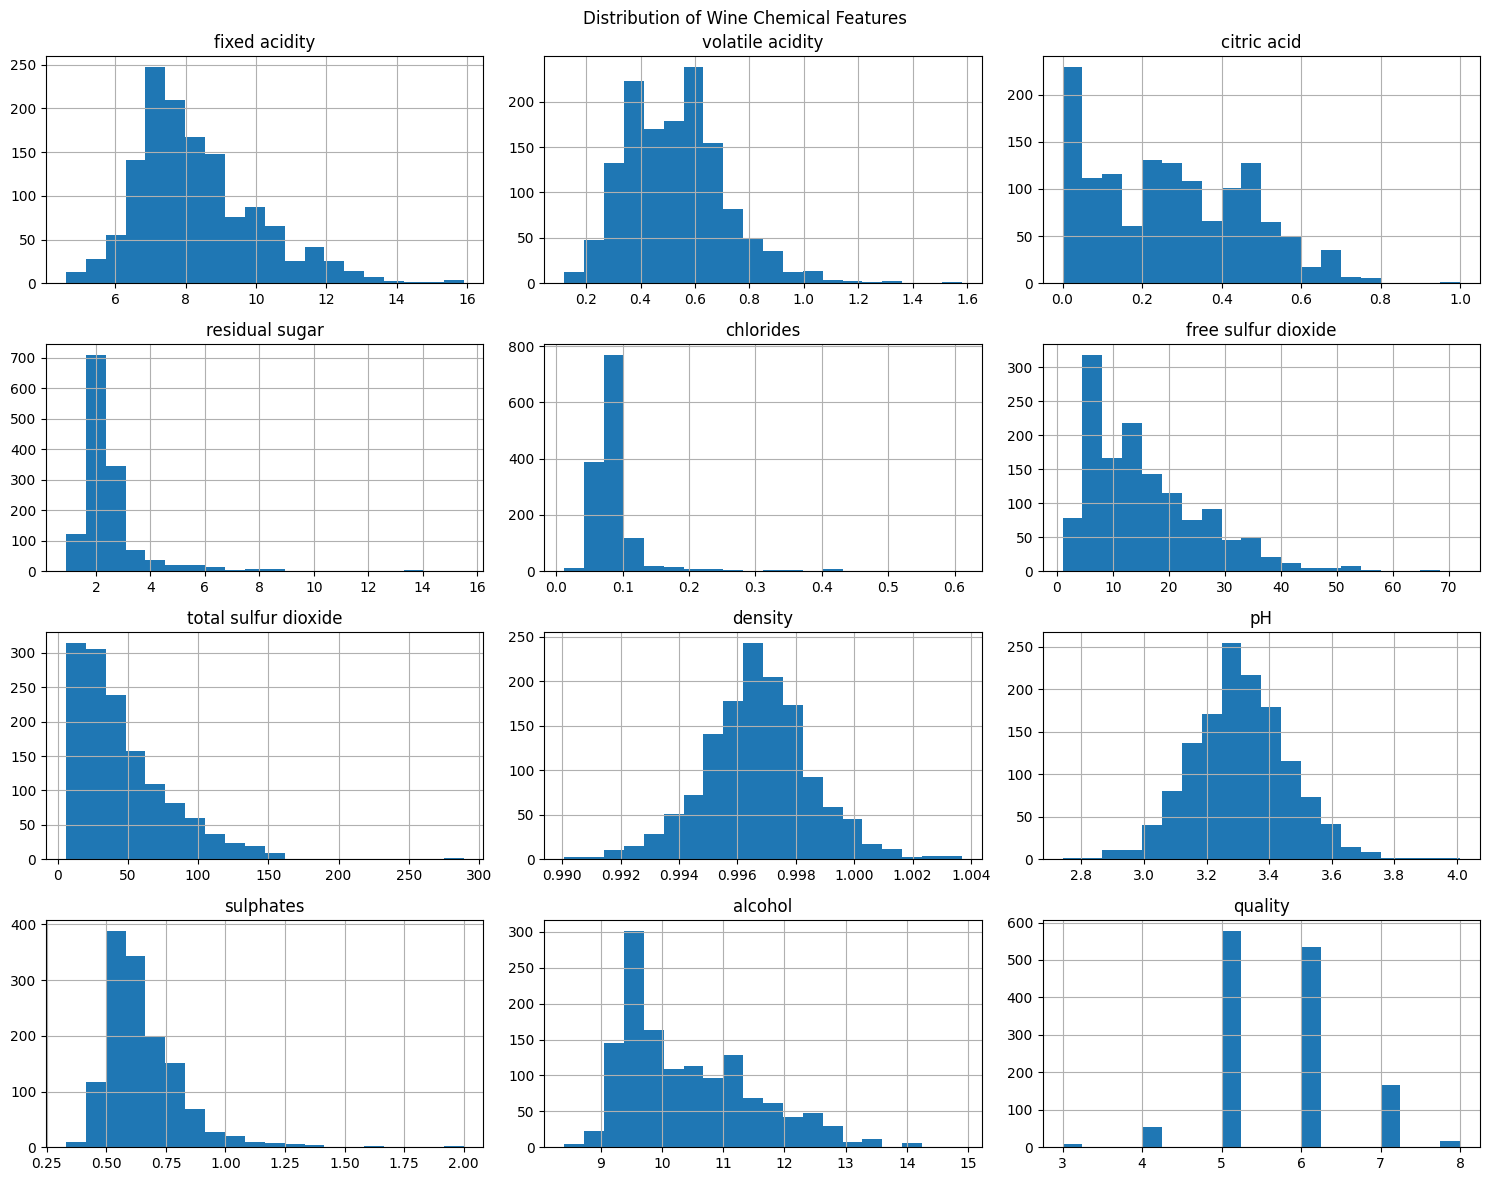

In [11]:
df.hist(figsize=(15, 12), bins=20)

plt.suptitle('Distribution of Wine Chemical Features')

plt.tight_layout()

plt.show()

The histograms show the distribution of all chemical properties in the wine dataset. Most features, such as residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide and sulphates, exhibit right-skewed distributions. Density and pH show relatively concentrated distributions. The wine quality scores are mainly concentrated around 5 and 6. These visualizations help understand the variation and distribution of different chemical features.

8. Correlation Analysis Using Heatmap

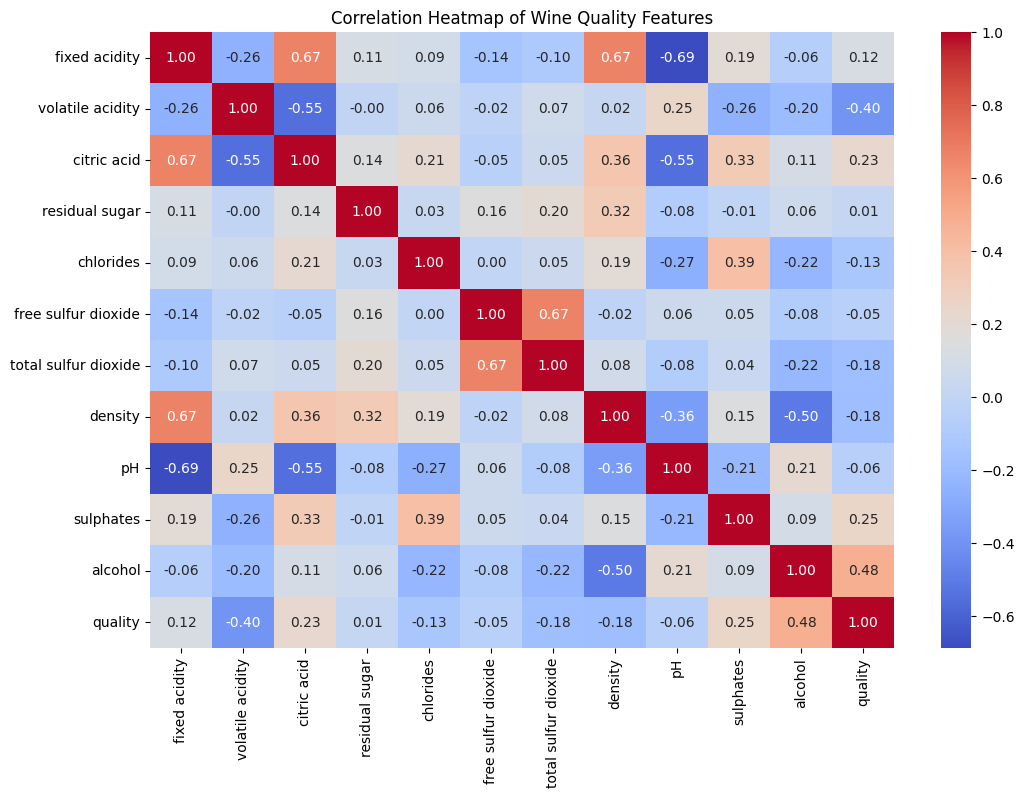

In [12]:
plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Wine Quality Features')

plt.show()

The correlation heatmap shows the relationships between different chemical properties and wine quality. Alcohol has the highest positive correlation with quality (0.48), indicating that higher alcohol content is associated with better wine quality. Volatile acidity shows the highest negative correlation (-0.40), indicating an inverse relationship with quality. Sulphates (0.25) and citric acid (0.23) show weak positive correlations. Other features have relatively weak correlations with wine quality.

9. Analysis of Class Imbalance

In [13]:
print("Quality Score Distribution:")
print(df['quality'].value_counts())

print("\nPercentage Distribution:")
print(df['quality'].value_counts(normalize=True) * 100)

Quality Score Distribution:
quality
5    577
6    535
7    167
4     53
8     17
3     10
Name: count, dtype: int64

Percentage Distribution:
quality
5    42.457689
6    39.367182
7    12.288447
4     3.899926
8     1.250920
3     0.735835
Name: proportion, dtype: float64


The quality score distribution shows that quality 5 has the highest number of samples (577), followed by quality 6 (535). Quality 3 has the lowest number of samples (10), followed by quality 8 (17). Most samples belong to quality scores 5 and 6, while very few belong to scores 3 and 8. Therefore, the dataset has an imbalanced class distribution, which may cause classification models to favor the majority classes.

10. Feature Engineering – Binary Classification

In [14]:
df['quality_label'] = df['quality'].apply(
    lambda x: 1 if x >= 6 else 0
)

print("Binary Quality Distribution:")
print(df['quality_label'].value_counts())

Binary Quality Distribution:
quality_label
1    719
0    640
Name: count, dtype: int64


The original wine quality scores were successfully converted into two categories: good quality (1) and bad quality (0). The dataset contains 719 good-quality samples and 640 bad-quality samples. The binary classes are relatively balanced, making the dataset suitable for binary classification.

11. Separating Input Features and Target Variable

In [15]:
X = df.drop(['quality', 'quality_label'], axis=1)

y = df['quality_label']

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (1359, 11)
Target Shape: (1359,)


The dataset was successfully divided into independent input features (X) and the target variable (y). The input features contain 11 chemical properties, while the target variable contains 1359 binary wine quality labels. These features will be used to train the classification models.

12. Splitting Data into Training and Testing Sets

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (1087, 11)
Testing Data Shape: (272, 11)

Training Target Distribution:
quality_label
1    575
0    512
Name: count, dtype: int64

Testing Target Distribution:
quality_label
1    144
0    128
Name: count, dtype: int64


The dataset was successfully divided into 80% training data (1087 samples) and 20% testing data (272 samples). Stratified sampling maintained the proportion of good-quality and bad-quality wine samples in both sets. The training data will be used for model building, while the testing data will be used for performance evaluation.

13. Feature Scaling Using StandardScaler

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

print("Scaled Training Data Shape:", X_train_scaled.shape)

print("Scaled Testing Data Shape:", X_test_scaled.shape)

Feature scaling completed successfully.
Scaled Training Data Shape: (1087, 11)
Scaled Testing Data Shape: (272, 11)


Feature scaling was successfully performed using StandardScaler. All 11 input features in the training and testing datasets were standardized while maintaining their original dimensions. This ensures that features with different measurement scales contribute appropriately to the SGD and SVC classification models.

14. Model 1 – Random Forest Classifier

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.7757352941176471


The Random Forest Classifier was successfully trained using 100 decision trees. The model achieved an accuracy of 77.57% on the testing dataset, indicating that it correctly predicts approximately 78% of the wine quality classifications.

15. Model 2 – Stochastic Gradient Descent (SGD) Classifier

In [19]:
from sklearn.linear_model import SGDClassifier

sgd_model = SGDClassifier(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

sgd_model.fit(X_train_scaled, y_train)

sgd_pred = sgd_model.predict(X_test_scaled)

print("SGD Accuracy:",
      accuracy_score(y_test, sgd_pred))

SGD Accuracy: 0.6691176470588235


The Stochastic Gradient Descent (SGD) classifier was successfully trained using standardized features. The model achieved an accuracy of 66.91% on the testing dataset. Its performance is lower than the Random Forest classifier, indicating that Random Forest currently provides better prediction accuracy.

16. Model 3 – Support Vector Classifier (SVC)

In [20]:
from sklearn.svm import SVC

svc_model = SVC(
    kernel='rbf',
    class_weight='balanced'
)

svc_model.fit(X_train_scaled, y_train)

svc_pred = svc_model.predict(X_test_scaled)

print("SVC Accuracy:",
      accuracy_score(y_test, svc_pred))

SVC Accuracy: 0.7610294117647058


The Support Vector Classifier (SVC) was successfully trained using standardized features with an RBF kernel. The model achieved an accuracy of 76.10% on the testing dataset. Its performance is better than SGD but slightly lower than Random Forest.

17.Compare the Accuracy of All Three Models

Random Forest: 77.57%
SGD: 66.91%
SVC: 76.10%


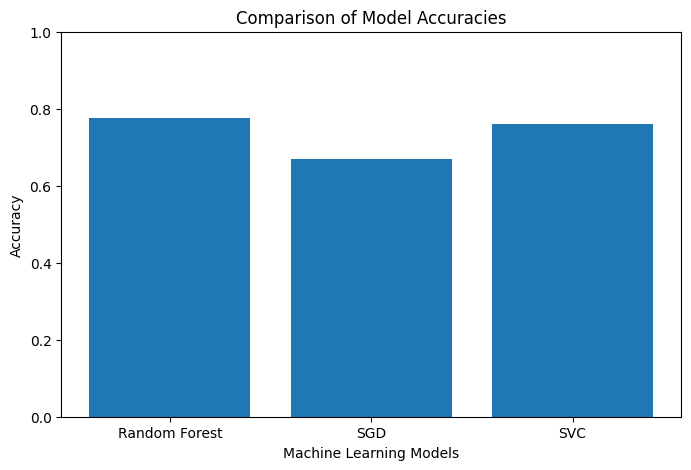

In [21]:
import matplotlib.pyplot as plt

models = ['Random Forest', 'SGD', 'SVC']
accuracies = [
    accuracy_score(y_test, rf_pred),
    accuracy_score(y_test, sgd_pred),
    accuracy_score(y_test, svc_pred)
]

for model, acc in zip(models, accuracies):
    print(f"{model}: {acc * 100:.2f}%")

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)
plt.title('Comparison of Model Accuracies')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

The bar graph compares the accuracy of three machine learning models. Random Forest achieved the highest accuracy of 77.57%, followed by SVC with 76.10% and SGD with 66.91%. Therefore, Random Forest is the best-performing model among the three based on test accuracy.

18.Classification Report

In [22]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report:")
print(classification_report(y_test, rf_pred))

print("SGD Classification Report:")
print(classification_report(y_test, sgd_pred))

print("SVC Classification Report:")
print(classification_report(y_test, svc_pred))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.77      0.76       128
           1       0.79      0.78      0.79       144

    accuracy                           0.78       272
   macro avg       0.77      0.78      0.78       272
weighted avg       0.78      0.78      0.78       272

SGD Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.83      0.70       128
           1       0.78      0.53      0.63       144

    accuracy                           0.67       272
   macro avg       0.69      0.68      0.67       272
weighted avg       0.70      0.67      0.66       272

SVC Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.81      0.76       128
           1       0.81      0.72      0.76       144

    accuracy                           0.76       272
   macro avg       0.76      0.76    

The Random Forest model achieved 78% accuracy. It showed good precision, recall, and F1-score for both classes. It provides balanced performance in predicting good and bad wine quality.

The SGD classifier achieved 67% accuracy. It showed higher recall for Class 0 than Class 1. Its lower recall and F1-score for Class 1 indicate that it missed several good-quality wine samples.

The SVC model achieved 76% accuracy. It showed good precision for Class 1 and balanced performance across both classes. Its overall performance was slightly lower than Random Forest.

19.Confusion Matrix

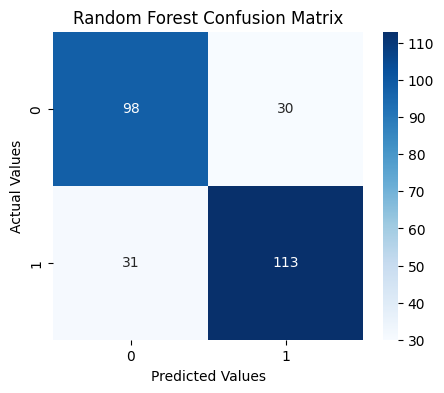

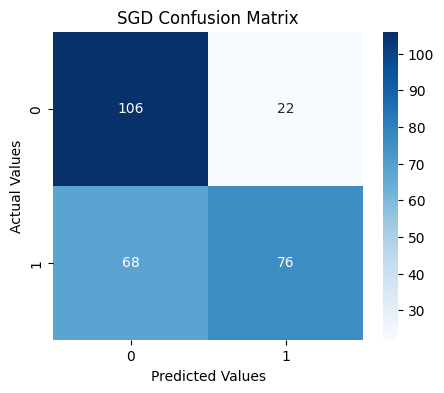

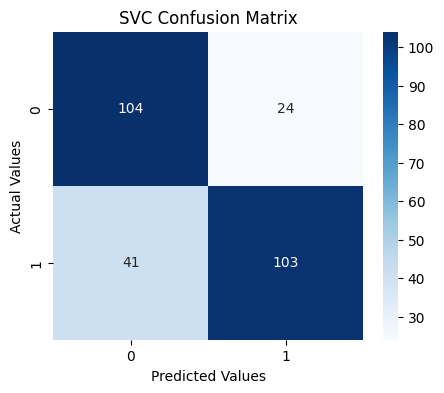

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

models = {
    'Random Forest': rf_pred,
    'SGD': sgd_pred,
    'SVC': svc_pred
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

    plt.title(f'{name} Confusion Matrix')
    plt.xlabel('Predicted Values')
    plt.ylabel('Actual Values')
    plt.show()

The confusion matrices compare the actual and predicted classifications of all three models. Random Forest correctly classified 211 samples, SVC classified 207 samples, and SGD classified 182 samples out of 272. Random Forest performed best, followed by SVC and SGD, based on the number of correct predictions.

20.Feature Importance Analysis

Feature Importance:
alcohol                 0.209351
sulphates               0.122430
volatile acidity        0.105289
total sulfur dioxide    0.092340
density                 0.088108
chlorides               0.072609
fixed acidity           0.069348
pH                      0.063495
citric acid             0.060835
free sulfur dioxide     0.058975
residual sugar          0.057220
dtype: float64


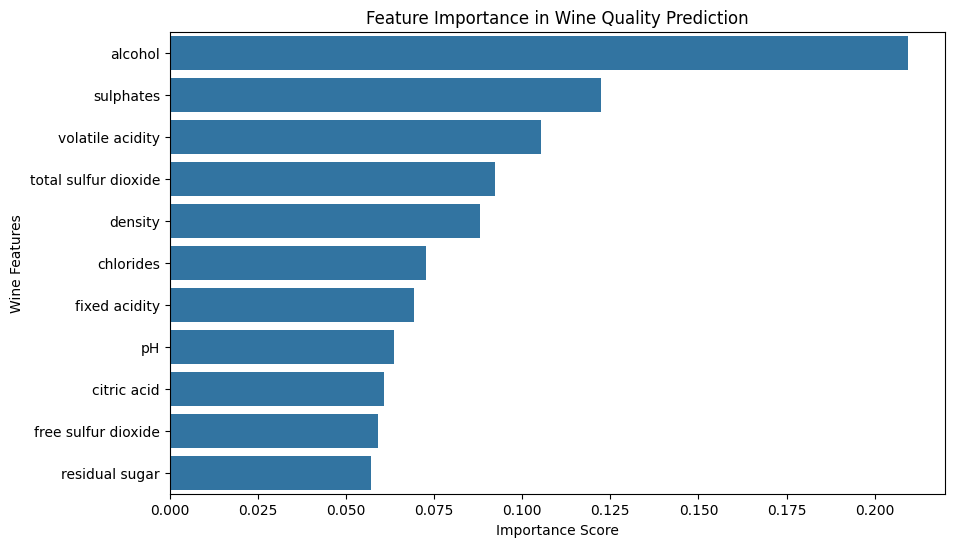

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.title('Feature Importance in Wine Quality Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Wine Features')
plt.show()

The feature importance graph shows that alcohol is the most influential feature in predicting wine quality, followed by sulphates and volatile acidity. Total sulfur dioxide, density, and chlorides also contribute to the predictions, while residual sugar has comparatively lower importance. This indicates that alcohol plays the major role in the Random Forest model's predictions.

Final Model Comparison

In [25]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'SGD', 'SVC'],
    'Accuracy': [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, sgd_pred),
        accuracy_score(y_test, svc_pred)
    ]
})

print(results)

best_model = results.loc[
    results['Accuracy'].idxmax()
]

print("\nBest Performing Model:")
print(best_model)

           Model  Accuracy
0  Random Forest  0.775735
1            SGD  0.669118
2            SVC  0.761029

Best Performing Model:
Model       Random Forest
Accuracy         0.775735
Name: 0, dtype: object


The comparison shows that Random Forest achieved the highest accuracy of 77.57%, followed by SVC with 76.10% and SGD with 66.91%. Therefore, Random Forest is selected as the best-performing model for wine quality prediction among the three models.

Project Conclusion

In this project, Wine Quality Prediction was performed using machine learning classification algorithms. The dataset was explored, cleaned, and preprocessed before training the models. Three algorithms, Random Forest, Stochastic Gradient Descent (SGD), and Support Vector Classifier (SVC), were implemented and evaluated.

Among the three models, Random Forest achieved the highest accuracy of 77.57%, followed by SVC (76.10%) and SGD (66.91%). Feature importance analysis identified alcohol as the most influential feature in the prediction process.

Thus, the project demonstrates how machine learning techniques can be used to predict wine quality based on its chemical properties.